# Klasifikasi Diagnosis Tumor Payudara — Regresi Logistik

Sistem klasifikasi biner **jinak (B) vs ganas (M)** menggunakan Regresi Logistik (scikit-learn) pada dataset Wisconsin Breast Cancer (`biner.csv`, 569 sampel, 30 fitur).

Alur: load data → pra-pemrosesan → splitting → training (pipeline scaling + logreg) → evaluasi (accuracy, precision, recall, F1, ROC-AUC) → interpretasi odds ratio.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
)

RANDOM_STATE = 42
TEST_SIZE = 0.2


## 1. Load & Pra-pemrosesan Data

In [2]:
df = pd.read_csv("biner.csv")
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]
df = df.drop(columns=["id"])

df["diagnosis"] = (df["diagnosis"] == "M").astype(int)
df = df.rename(columns={"diagnosis": "ganas"})

print(f"Dimensi: {df.shape}")
print(f"Distribusi kelas (1=ganas):\n{df['ganas'].value_counts().sort_index()}")
df.head()


Dimensi: (569, 31)
Distribusi kelas (1=ganas):
ganas
0    357
1    212
Name: count, dtype: int64


,ganas,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


- `id` dibuang (hanya identifier, bukan prediktor)
- `ganas`: M → 1, B → 0

## 2. Split Data

In [3]:
X = df.drop(columns=["ganas"])
y = df["ganas"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]} sampel | Test: {X_test.shape[0]} sampel")
print(f"Rasio ganas — train: {y_train.mean():.2%}, test: {y_test.mean():.2%}")


Train: 455 sampel | Test: 114 sampel
Rasio ganas — train: 37.36%, test: 36.84%


## 3. Training — Pipeline (StandardScaler + LogisticRegression)

Scaling diperlukan agar koefisien fitur sebanding (feature scale rata-rata ~0–1000-an, sangat beragam).


In [4]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)),
])

model.fit(X_train, y_train)
print("Training selesai.")


Training selesai.


## 4. Evaluasi

In [5]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_proba),
}

for name, value in metrics.items():
    print(f"{name:>10}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Jinak (B)", "Ganas (M)"]))


  Accuracy: 0.9649
 Precision: 0.9750
    Recall: 0.9286
  F1-Score: 0.9512
   ROC-AUC: 0.9960

Classification Report:
              precision    recall  f1-score   support

   Jinak (B)       0.96      0.99      0.97        72
   Ganas (M)       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



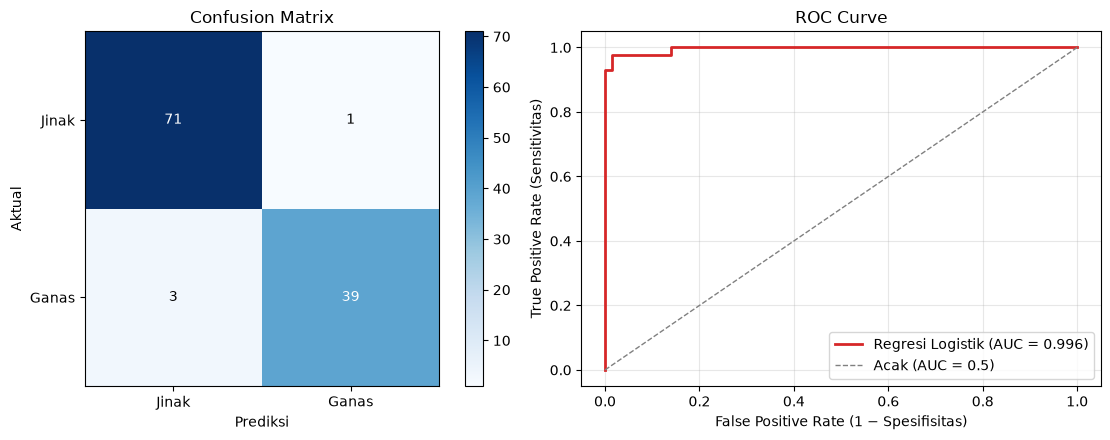

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred)
im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks([0, 1], ["Jinak", "Ganas"])
axes[0].set_yticks([0, 1], ["Jinak", "Ganas"])
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")
axes[0].set_title("Confusion Matrix")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, ax=axes[0], fraction=0.046)

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color="tab:red", lw=2,
             label=f"Regresi Logistik (AUC = {metrics['ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], ls="--", color="gray", lw=1, label="Acak (AUC = 0.5)")
axes[1].set_xlabel("False Positive Rate (1 − Spesifisitas)")
axes[1].set_ylabel("True Positive Rate (Sensitivitas)")
axes[1].set_title("ROC Curve")
axes[1].legend(loc="lower right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Interpretasi Koefisien (Odds Ratio)

Odds ratio = e^β per fitur (pada fitur terskalakan). OR > 1 → kenaikan fitur menaikkan peluang ganas; OR < 1 → menurunkan.


In [7]:
logreg = model.named_steps["logreg"]
coef_df = pd.DataFrame({
    "fitur": X.columns,
    "beta": logreg.coef_[0],
    "odds_ratio": np.exp(logreg.coef_[0]),
}).sort_values("beta", key=abs, ascending=False)

print("10 fitur dengan pengaruh terbesar:")
coef_df.head(10).reset_index(drop=True)


10 fitur dengan pengaruh terbesar:


,fitur,beta,odds_ratio
0,texture_worst,1.434093,4.195838
1,radius_se,1.233325,3.432625
2,symmetry_worst,1.061264,2.890021
3,concave points_mean,0.952813,2.592993
4,concavity_worst,0.911406,2.487817
5,area_se,0.909029,2.481912
6,compactness_se,-0.906925,0.403764
7,area_worst,0.900477,2.460776
8,radius_worst,0.896968,2.452156
9,concavity_mean,0.782298,2.186492


## Kesimpulan

- Model regresi logistik dilatih dengan stratified split 80/20 dan pipeline scaling.
- Metrik utama: accuracy, precision, recall, F1, dan ROC-AUC pada data uji (lihat tabel metrik di atas).
- Fitur `*_worst` (khususnya area/perimeter/concave points worst) umumnya mendominasi odds ratio — sesuai domain, ukuran maksimal sel tumor berkorelasi kuat dengan keganasan.
- Untuk konteks medis, **recall (sensitivitas) kelas ganas** adalah kunci: salah deteksi ganas sebagai jinak (FN) jauh lebih berbahaya daripada sebaliknya.
